# Задание 1.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_diabetes
from IPython.display import display

sns.set_style("whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 1.1 Загрузка данных

In [ ]:
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Размер X:", X.shape)
print("Размер y:", y.shape)
print("Описание:")
print(data.DESCR[:800])

Размер X: (442, 10)
Размер y: (442,)
Описание:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipo


## 1.2 Описание данных, характер цели, полнота

Проверяем: типы, пропуски, дубликаты, характер целевой переменной.

In [ ]:
display(X.head())
X.info()
display(y.describe())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


In [ ]:
missing_X = X.isnull().mean() * 100
missing_y = y.isnull().mean() * 100
print("Признаки с пропусками:", missing_X[missing_X > 0].to_dict() or "нет")
print("Пропуски в y (%):", missing_y)
print("Дубликатов в X:", X.duplicated().sum())
print("Дубликатов в y:", y.duplicated().sum())
print("Тип цели:", y.dtype)
print("Уникальных значений цели:", y.nunique())
print("Мин/макс цели:", y.min(), "/", y.max())

Признаки с пропусками: нет
Пропуски в y (%): 0.0
Дубликатов в X: 0
Дубликатов в y: 228
Тип цели: float64
Уникальных значений цели: 214
Мин/макс цели: 25.0 / 346.0


**Вывод по 1.2:**

- Целевая переменная target — непрерывная, 442 наблюдения.
- Пропусков и дубликатов в X — данные полные.
- 10 признаков, все float64.

## 1.3 Гистограмма целевой переменной

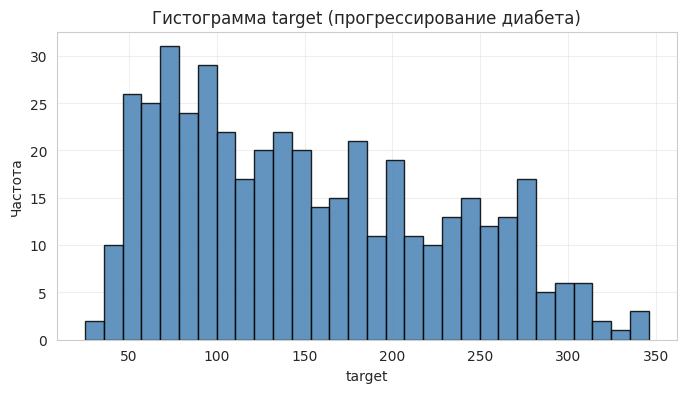

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(y, bins=30, color="steelblue", edgecolor="black", alpha=0.85)
plt.title("Гистограмма target (прогрессирование диабета)")
plt.xlabel("target")
plt.ylabel("Частота")
plt.grid(alpha=0.3)
plt.show()

## 1.4 Гистограммы для всех признаков

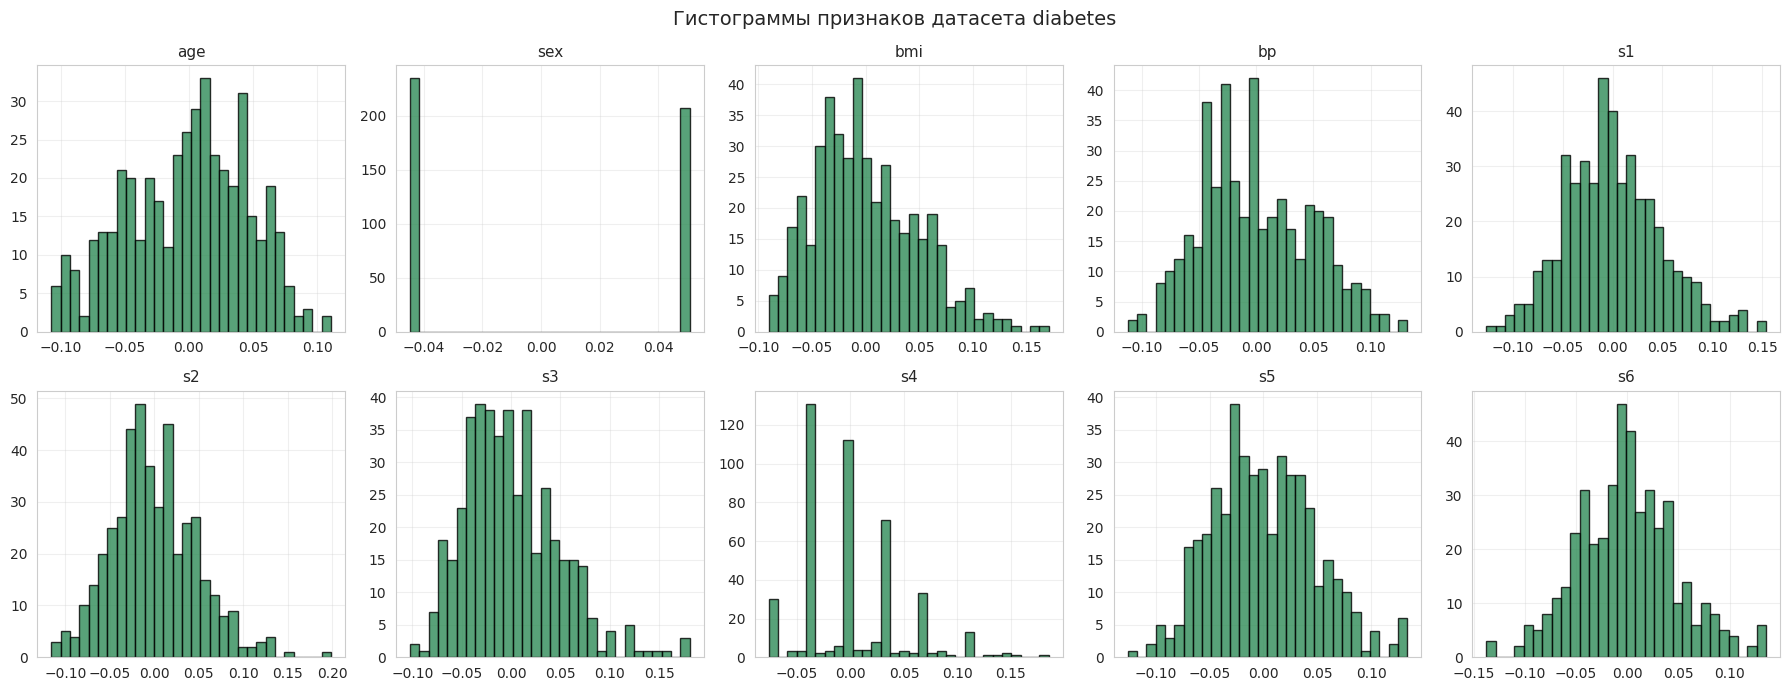

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), X.columns):
    ax.hist(X[col], bins=30, color="seagreen", edgecolor="black", alpha=0.8)
    ax.set_title(col, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle("Гистограммы признаков датасета diabetes", fontsize=14)
plt.tight_layout()
plt.show()

## 1.5 Визуальная оценка характера распределения

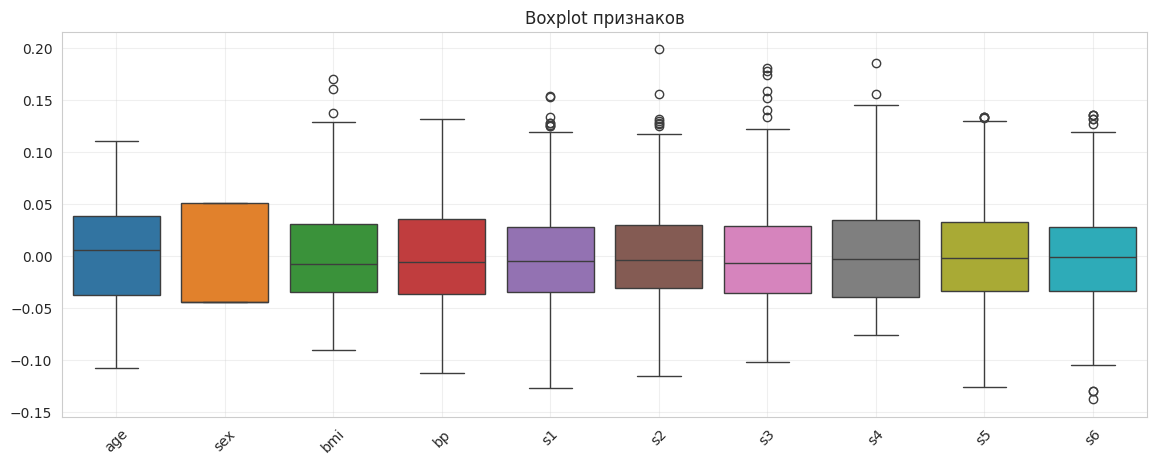

In [ ]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=X)
plt.xticks(rotation=45)
plt.title("Boxplot признаков")
plt.grid(alpha=0.3)
plt.show()

## 1.6 Тесты нормальности

In [ ]:
def normality_report(series, name):
    s = series.dropna().values
    sh_stat, sh_p = stats.shapiro(s)
    dp_stat, dp_p = stats.normaltest(s)
    ks_stat, ks_p = stats.kstest((s - s.mean()) / s.std(), "norm")
    print(f"{name:>8} | Shapiro p={sh_p:.3e} | D'Agostino p={dp_p:.3e} | KS p={ks_p:.3e}")

normality_report(y, "target")
for col in X.columns:
    normality_report(X[col], col)

  target | Shapiro p=3.364e-11 | D'Agostino p=1.174e-14 | KS p=5.340e-04
     age | Shapiro p=3.278e-05 | D'Agostino p=1.023e-05 | KS p=6.703e-02
     sex | Shapiro p=1.398e-29 | D'Agostino p=0.000e+00 | KS p=3.977e-51
     bmi | Shapiro p=2.520e-07 | D'Agostino p=7.262e-06 | KS p=2.463e-02
      bp | Shapiro p=7.135e-05 | D'Agostino p=4.054e-04 | KS p=1.385e-02
      s1 | Shapiro p=5.129e-03 | D'Agostino p=3.682e-03 | KS p=1.909e-01
      s2 | Shapiro p=1.309e-03 | D'Agostino p=1.215e-04 | KS p=2.161e-01
      s3 | Shapiro p=4.434e-09 | D'Agostino p=4.007e-11 | KS p=1.478e-02
      s4 | Shapiro p=3.274e-14 | D'Agostino p=1.301e-08 | KS p=1.775e-11
      s5 | Shapiro p=9.556e-03 | D'Agostino p=3.950e-02 | KS p=1.564e-01
      s6 | Shapiro p=4.095e-02 | D'Agostino p=1.167e-01 | KS p=2.514e-01


**Вывод по 1.6:**

При все признаки и цель отвергают нормальность. Нужно чтоб все тесты были меньше 0.05

## 1.7 Основные статистики для X и y

In [ ]:
display(X.describe().T)
display(y.describe())

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


In [ ]:
stats_table = pd.DataFrame({
    "mean":   [X.mean().mean(),  y.mean()],
    "median": [X.median().median(), y.median()],
    "std":    [X.std().mean(),   y.std()],
    "skew":   [X.skew().mean(),  y.skew()],
    "kurt":   [X.kurt().mean(),  y.kurt()],
}, index=["X (усреднённо все признаки)", "y"])
display(stats_table)

,mean,median,std,skew,kurt
X (усреднённо все признаки),-1.662891e-17,-0.00407,0.047619,0.363381,-0.073895
y,1.521335e+02,140.50000,77.093005,0.440563,-0.883057


## 1.8 Анализ выбросов и итоговое резюме

In [ ]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < low) | (series > high)).sum()), low, high

print(f"{'признак':>8} | выбросов | границы")
for col in X.columns:
    n_out, lo, hi = iqr_outliers(X[col])
    print(f"{col:>8} | {n_out:>8} | [{lo:.3f}; {hi:.3f}]")
n_out_y, lo_y, hi_y = iqr_outliers(y)
print(f"{'target':>8} | {n_out_y:>8} | [{lo_y:.3f}; {hi_y:.3f}]")

 признак | выбросов | границы
     age |        0 | [-0.150; 0.151]
     sex |        0 | [-0.188; 0.194]
     bmi |        3 | [-0.132; 0.129]
      bp |        0 | [-0.145; 0.144]
      s1 |        8 | [-0.128; 0.122]
      s2 |        7 | [-0.121; 0.120]
      s3 |        7 | [-0.132; 0.126]
      s4 |        2 | [-0.150; 0.145]
      s5 |        4 | [-0.132; 0.131]
      s6 |        9 | [-0.125; 0.120]
  target |        0 | [-99.750; 398.250]


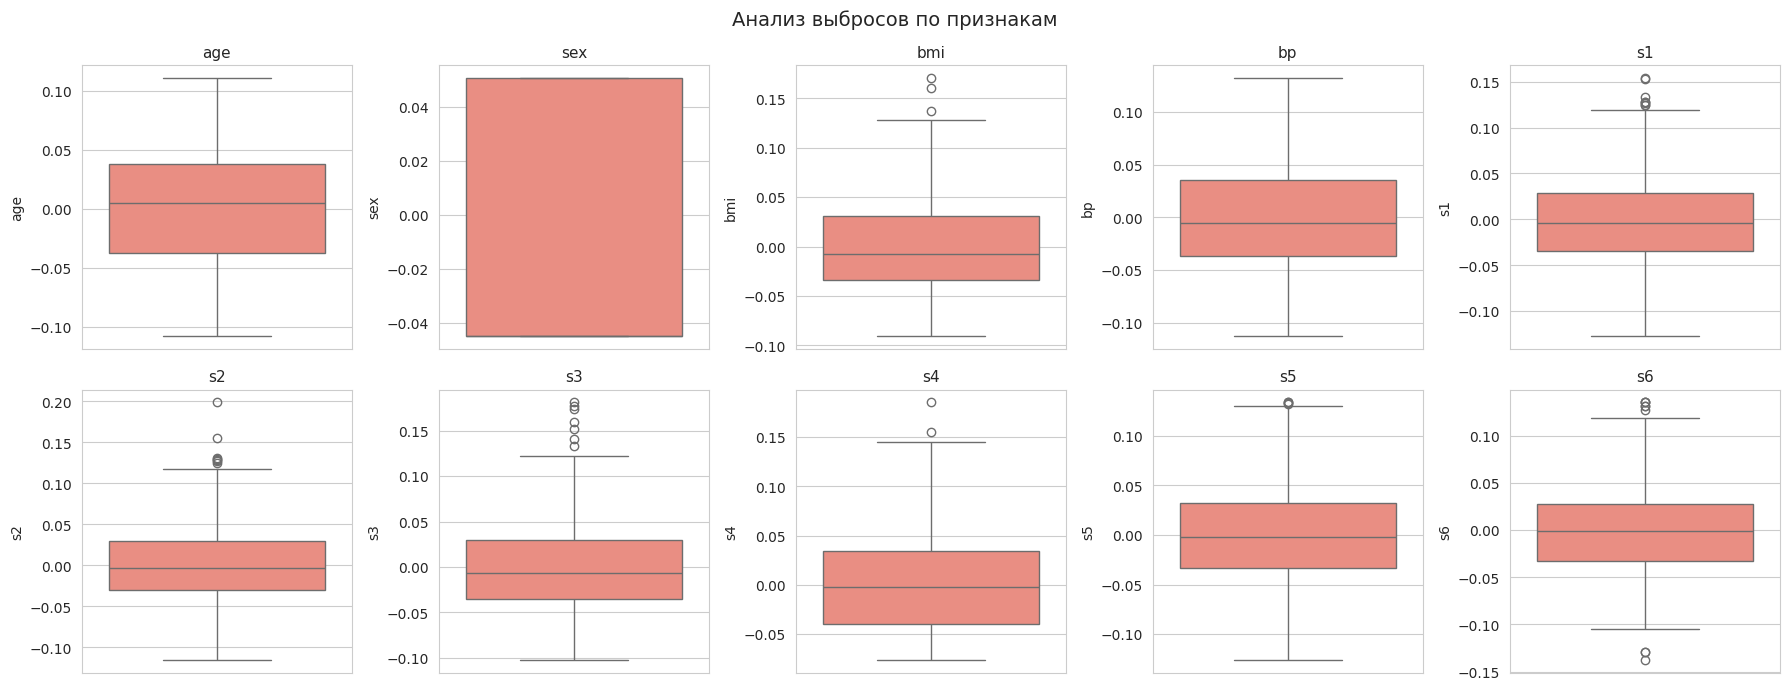

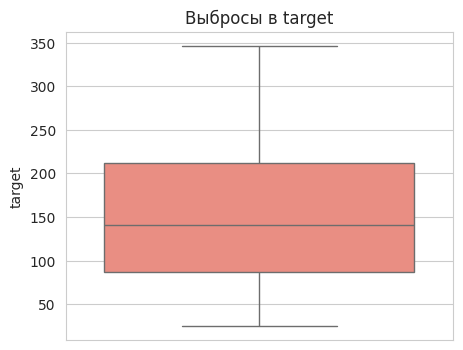

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), X.columns):
    sns.boxplot(y=X[col], ax=ax, color="salmon")
    ax.set_title(col, fontsize=11)
plt.suptitle("Анализ выбросов по признакам", fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.boxplot(y=y, color="salmon")
plt.title("Выбросы в target")
plt.show()

### Итоговое резюме по заданию 1

1. Пропуски и дубликаты: отсутствуют — данные чистые.
2. Типы: все 10 признаков числовые float64, target — float64.
3. Нормальность: отвергается для всех признаков и цели (Shapiro, D'Agostino, KS, p ≪ 0.05).
4. Выбросы (по IQR): присутствуют в bmi, s_i (единичное число).
   - Удалять их без обоснования не рекомендуется: выборка мала (442), значения могут отражать реальную клиническую вариабельность.
5. Общее качество данных: высокое. Данные полные, пригодны для моделирования. При построении моделей учесть наличие выбросов.

# Задание 2. Генерация синтетических данных в scikit-learn

Знакомимся с методами `make_classification` и `make_blobs`. Для каждого набора проводим анализ признаков: основные статистики, гистограммы, оценка нормальности.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn import datasets
from IPython.display import display

sns.set_style("whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2.1 Создание синтетического набора через `make_classification`

Параметры:
- n_samples = 1000
- n_informative = 3
- n_redundant = 3
- n_classes = 3
- n_clusters_per_class = 2

In [ ]:
# n_features = n_informative + n_redundant = 3 + 3 = 6
X_cls, y_cls = datasets.make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=3,
    n_redundant=3,
    n_classes=3,
    n_clusters_per_class=2,
    random_state=42
)

print("X_cls shape:", X_cls.shape)
print("y_cls shape:", y_cls.shape)
print("Классы:", np.unique(y_cls, return_counts=True))

X_cls shape: (1000, 6)
y_cls shape: (1000,)
Классы: (array([0, 1, 2]), array([333, 335, 332]))


## 2.2 Анализ признаков `make_classification`

### 2.2.1 Основные статистики

In [ ]:
Xc = pd.DataFrame(X_cls, columns=[f"f{i}" for i in range(X_cls.shape[1])])
yc = pd.Series(y_cls, name="target")

display(Xc.describe().T)

,count,mean,std,min,25%,50%,75%,max
f0,1000.0,-0.347635,1.381117,-4.659960,-1.286116,-0.611881,0.623235,3.921778
f1,1000.0,0.055339,1.240593,-3.818368,-0.915044,0.217239,1.029018,3.193903
f2,1000.0,0.125913,1.100189,-4.033177,-0.774956,0.222896,0.961203,2.744621
f3,1000.0,0.191686,1.514928,-4.550023,-0.791206,0.143751,1.284914,4.944153
f4,1000.0,0.254019,1.517473,-4.483158,-0.569036,0.342156,1.275319,5.017518
f5,1000.0,0.051375,1.351749,-3.680880,-1.016139,0.055528,1.058421,3.969755


In [ ]:
# Расширенные статистики по признакам
ext = pd.DataFrame({
    "mean":   Xc.mean(),
    "std":    Xc.std(),
    "skew":   Xc.skew(),
    "kurt":   Xc.kurt(),
    "min":    Xc.min(),
    "max":    Xc.max(),
})
display(ext)

,mean,std,skew,kurt,min,max
f0,-0.347635,1.381117,0.413991,-0.123679,-4.659960,3.921778
f1,0.055339,1.240593,-0.290083,-0.675252,-3.818368,3.193903
f2,0.125913,1.100189,-0.156289,-0.604040,-4.033177,2.744621
f3,0.191686,1.514928,-0.093442,-0.108213,-4.550023,4.944153
f4,0.254019,1.517473,-0.359595,0.131933,-4.483158,5.017518
f5,0.051375,1.351749,-0.042787,-0.520670,-3.680880,3.969755


### 2.2.2 Гистограммы признаков

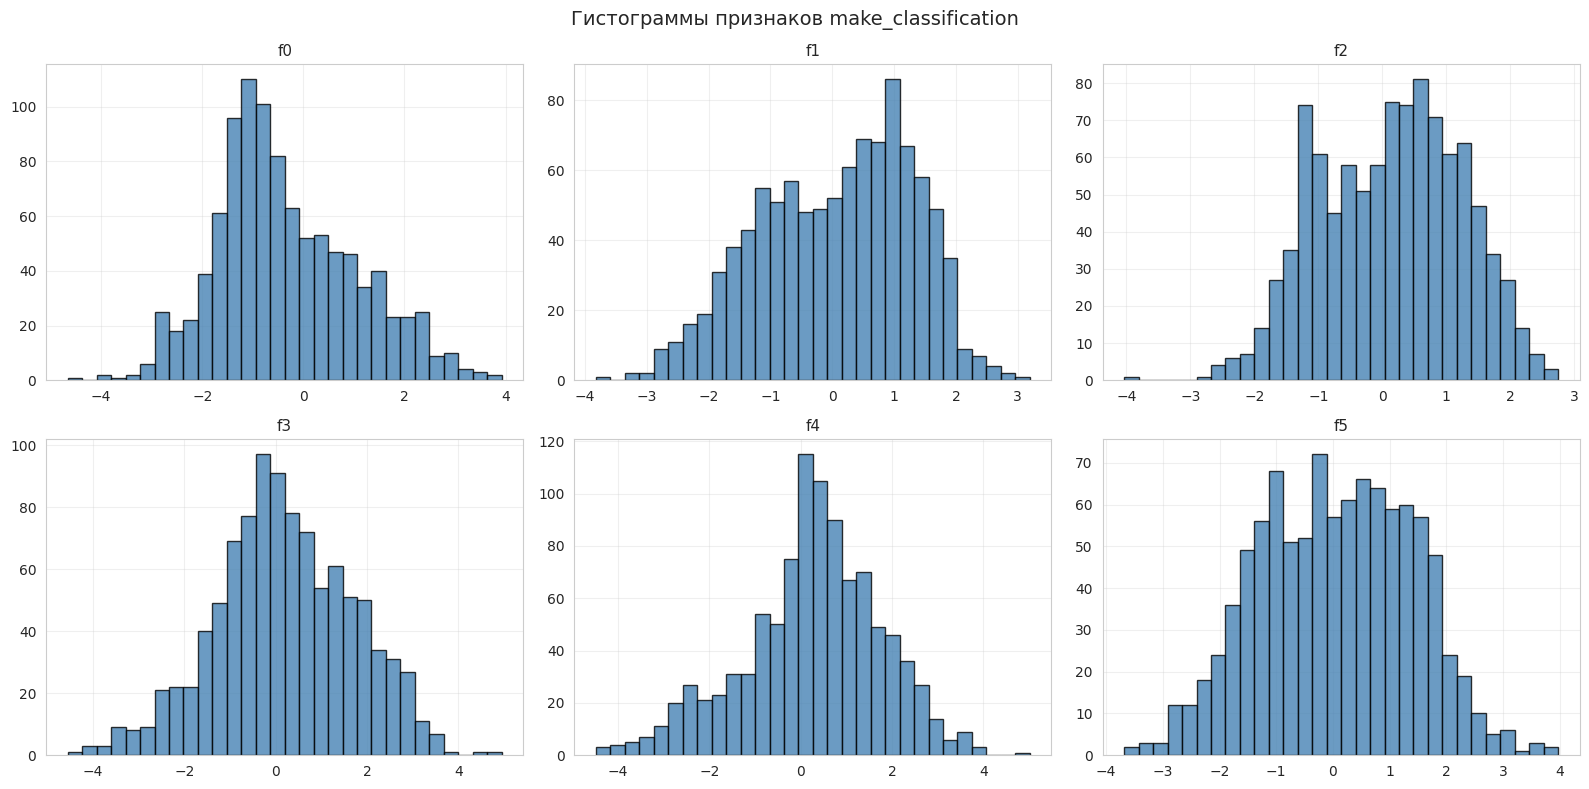

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), Xc.columns):
    ax.hist(Xc[col], bins=30, color="steelblue", edgecolor="black", alpha=0.8)
    ax.set_title(col, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle("Гистограммы признаков make_classification", fontsize=14)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1913/2668403755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=yc, palette="viridis")


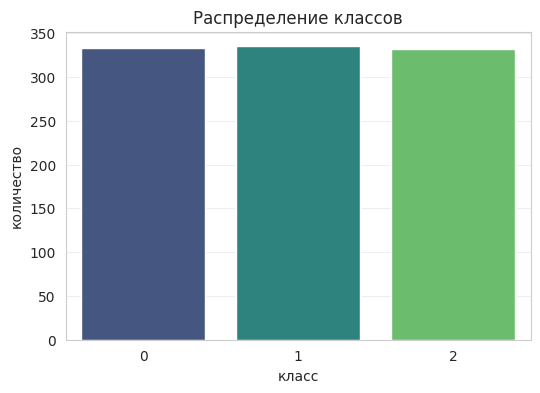

In [ ]:
# Распределение цели
plt.figure(figsize=(6, 4))
sns.countplot(x=yc, palette="viridis")
plt.title("Распределение классов")
plt.xlabel("класс")
plt.ylabel("количество")
plt.grid(alpha=0.3, axis="y")
plt.show()

### 2.2.3 Оценка нормальности

Применим Shapiro-Wilk и D'Agostino-Pearson.

In [ ]:
def normality_report(series, name):
    s = series.dropna().values
    sh_stat, sh_p = stats.shapiro(s)
    dp_stat, dp_p = stats.normaltest(s)
    ks_stat, ks_p = stats.kstest((s - s.mean()) / s.std(), "norm")
    verdict_sh = "норм." if sh_p > 0.05 else "не норм."
    verdict_dp = "норм." if dp_p > 0.05 else "не норм."
    verdict_ks = "норм." if ks_p > 0.05 else "не норм."
    print(f"{name:>5} | Shapiro p={sh_p:.3e} ({verdict_sh}) | "
          f"D'Agostino p={dp_p:.3e} ({verdict_dp}) | "
          f"KS p={ks_p:.3e} ({verdict_ks})")

print(f"{'признак':>5} | результаты тестов нормальности")
for col in Xc.columns:
    normality_report(Xc[col], col)

признак | результаты тестов нормальности
   f0 | Shapiro p=2.160e-10 (не норм.) | D'Agostino p=1.134e-06 (не норм.) | KS p=2.463e-06 (не норм.)
   f1 | Shapiro p=2.347e-10 (не норм.) | D'Agostino p=1.419e-13 (не норм.) | KS p=3.311e-04 (не норм.)
   f2 | Shapiro p=1.121e-07 (не норм.) | D'Agostino p=1.381e-08 (не норм.) | KS p=1.289e-02 (не норм.)
   f3 | Shapiro p=1.973e-02 (не норм.) | D'Agostino p=3.836e-01 (норм.) | KS p=6.886e-01 (норм.)
   f4 | Shapiro p=2.138e-07 (не норм.) | D'Agostino p=2.328e-05 (не норм.) | KS p=1.317e-03 (не норм.)
   f5 | Shapiro p=2.560e-04 (не норм.) | D'Agostino p=2.577e-05 (не норм.) | KS p=5.870e-02 (норм.)


### 2.2.4 Визуализация: Q-Q plots и распределение по классам

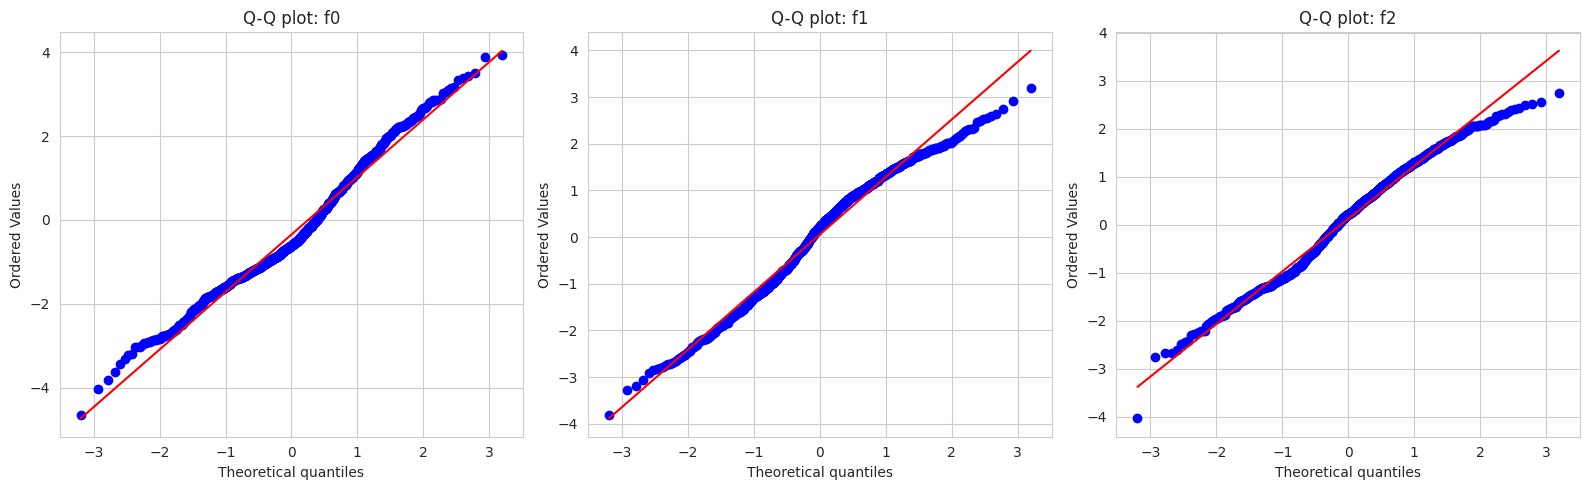

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["f0", "f1", "f2"]):
    stats.probplot(Xc[col], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {col}")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1913/2142591263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=yc, y=Xc[col], ax=ax, palette="viridis")
/tmp/ipykernel_1913/2142591263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=yc, y=Xc[col], ax=ax, palette="viridis")
/tmp/ipykernel_1913/2142591263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=yc, y=Xc[col], ax=ax, palette="viridis")
/tmp/ipykernel_1913/2142591263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to 

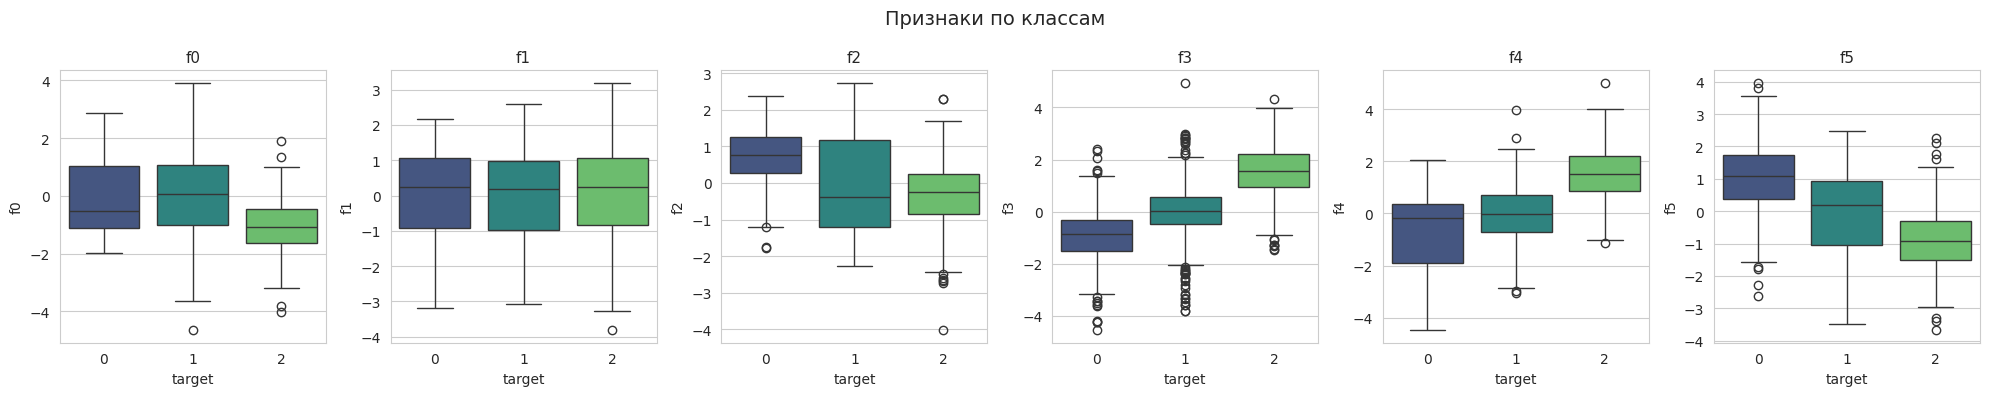

In [ ]:
# Boxplot по признакам в разрезе классов
fig, axes = plt.subplots(1, Xc.shape[1], figsize=(20, 4))
for ax, col in zip(axes, Xc.columns):
    sns.boxplot(x=yc, y=Xc[col], ax=ax, palette="viridis")
    ax.set_title(col, fontsize=11)
plt.suptitle("Признаки по классам", fontsize=14)
plt.tight_layout()
plt.show()

## 2.3 Создание синтетического набора через `make_blobs`

Параметры:
- n_samples = 1000
- centers = 3
- n_features = 2

In [ ]:
X_bl, y_bl = datasets.make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    random_state=42
)

print("X_bl shape:", X_bl.shape)
print("y_bl shape:", y_bl.shape)
print("Классы:", np.unique(y_bl, return_counts=True))

X_bl shape: (1000, 2)
y_bl shape: (1000,)
Классы: (array([0, 1, 2]), array([334, 333, 333]))


## 2.4 Анализ признаков `make_blobs`

### 2.4.1 Основные статистики

In [ ]:
Xb = pd.DataFrame(X_bl, columns=["x0", "x1"])
yb = pd.Series(y_bl, name="target")

display(Xb.describe().T)

ext_b = pd.DataFrame({
    "mean": Xb.mean(),
    "std":  Xb.std(),
    "skew": Xb.skew(),
    "kurt": Xb.kurt(),
})
display(ext_b)

,count,mean,std,min,25%,50%,75%,max
x0,1000.0,-1.554994,4.879199,-9.582859,-6.182815,-2.493024,4.081315,7.199963
x1,1000.0,1.432353,6.544595,-9.820498,-6.120279,2.133529,8.325314,12.867018


,mean,std,skew,kurt
x0,-1.554994,4.879199,0.271629,-1.395276
x1,1.432353,6.544595,-0.144173,-1.432939


### 2.4.2 Гистограммы признаков

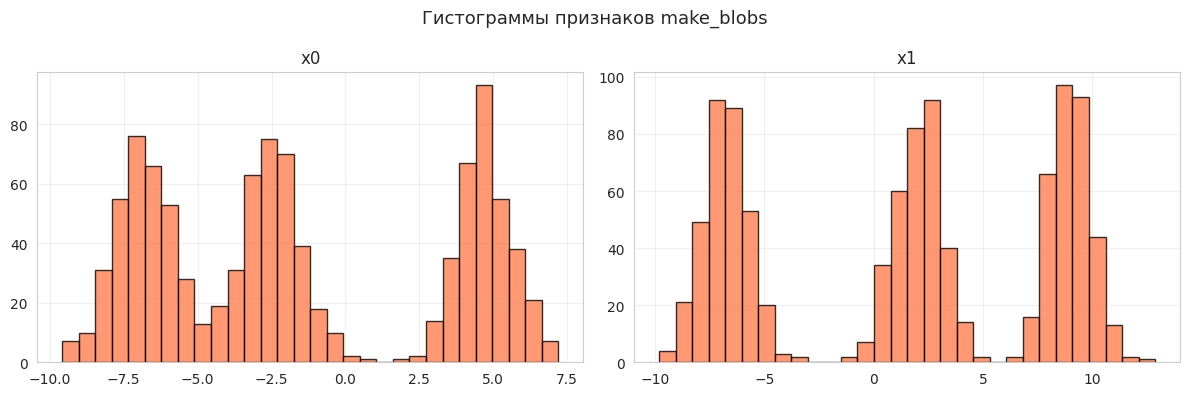

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, Xb.columns):
    ax.hist(Xb[col], bins=30, color="coral", edgecolor="black", alpha=0.8)
    ax.set_title(col)
    ax.grid(alpha=0.3)
plt.suptitle("Гистограммы признаков make_blobs", fontsize=13)
plt.tight_layout()
plt.show()

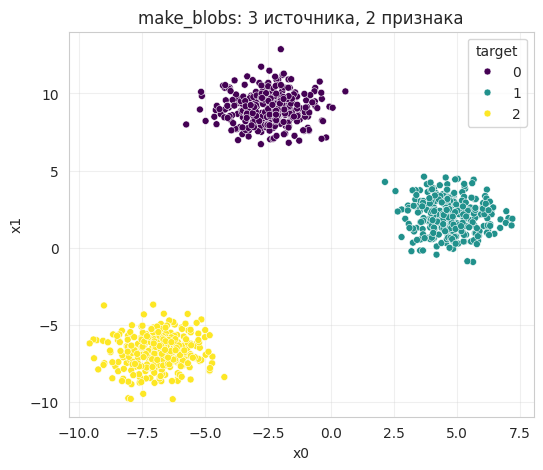

In [ ]:
# Скаттер по классам
plt.figure(figsize=(6, 5))
sns.scatterplot(x=Xb["x0"], y=Xb["x1"], hue=yb, palette="viridis", s=25)
plt.title("make_blobs: 3 источника, 2 признака")
plt.grid(alpha=0.3)
plt.show()

### 2.4.3 Оценка нормальности

In [ ]:
print(f"{'признак':>5} | результаты тестов нормальности")
for col in Xb.columns:
    normality_report(Xb[col], col)

признак | результаты тестов нормальности
   x0 | Shapiro p=1.304e-25 (не норм.) | D'Agostino p=0.000e+00 (не норм.) | KS p=3.097e-22 (не норм.)
   x1 | Shapiro p=2.426e-26 (не норм.) | D'Agostino p=0.000e+00 (не норм.) | KS p=1.063e-22 (не норм.)


### 2.4.4 Q-Q plots

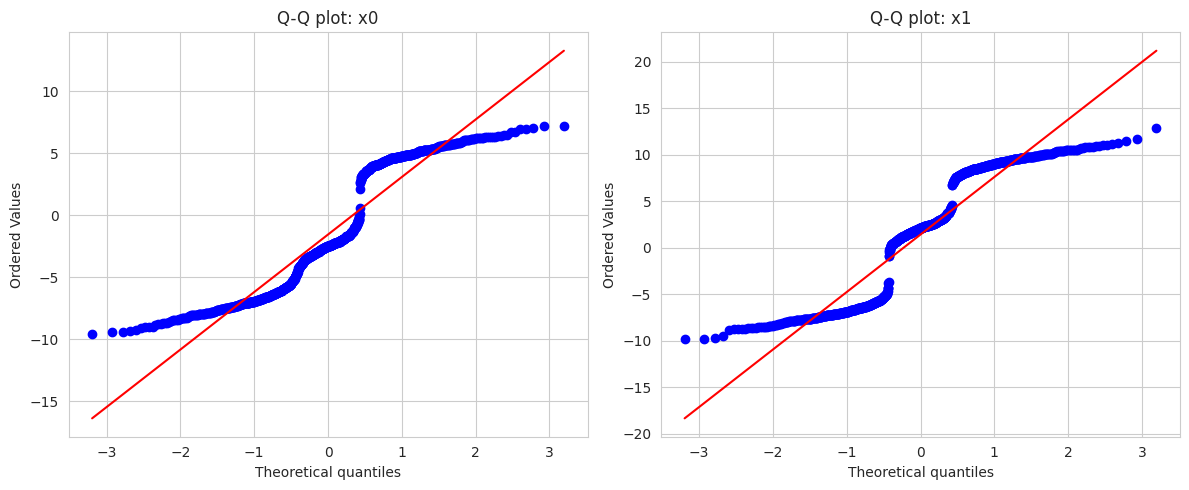

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, Xb.columns):
    stats.probplot(Xb[col], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {col}")
plt.tight_layout()
plt.show()

## Итоговое резюме по заданию 2

### make_classification (3 класса, 3 инф. + 3 избыт.)
- Признаки — близки к нормальному распределению, но строго если говорить, то не является таковыми.
- Классы сбалансированы.

### make_blobs (3 центра, 2 признака)
- Каждый признак не обладает нормальным распределением.
- Данные идеальны для разделения по классам.

# Задание 3. EDA для Solar.csv

Вариант 6: Solar.csv.

Y = Radiation. X = UNIXTime, Data, Time, Temperature, Pressure, Humidity,
WindDirection(Degrees), Speed, TimeSunRise, TimeSunSet.

План:
1. Открытие датасета
2. Приведение к табличной форме
3. Описание переменных
4. Число примеров, X и y
5. Гипотезы о распределениях + анализ
6. Оценка пропусков
7. Вариант ML-задачи

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_style("whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
np.random.seed(42)

## 1. Открытие датасета

In [ ]:
df = pd.read_csv("Solar.csv")
print("Размер:", df.shape)
print("Колонки:", df.columns.tolist())
display(df.head())
print(df.dtypes)

Размер: (32686, 11)
Колонки: ['UNIXTime', 'Data', 'Time', 'Radiation', 'Temperature', 'Pressure', 'Humidity', 'WindDirection(Degrees)', 'Speed', 'TimeSunRise', 'TimeSunSet']


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


UNIXTime                    int64
Data                       object
Time                       object
Radiation                 float64
Temperature                 int64
Pressure                  float64
Humidity                    int64
WindDirection(Degrees)    float64
Speed                     float64
TimeSunRise                object
TimeSunSet                 object
dtype: object


## 2. Переход от табличной формы к не-табличной

Solar.csv — уже таблица (CSV с колонками). По условию: «или обратно, если в наборе таблица», так что нужно уйти от табличного представления (и наверно временно, так как удобнее далее все в табличном делать).

Показываем в виде NumPy-массив (тензор): матрица (n, m) — «плоская» числовая форма.


In [ ]:
df["datetime"] = pd.to_datetime(df["UNIXTime"], unit="s", errors="coerce")
df = df.sort_values("datetime").reset_index(drop=True)

numeric_cols = ["Radiation", "Temperature", "Pressure", "Humidity",
                "WindDirection(Degrees)", "Speed"]
arr = df[numeric_cols].to_numpy()
print(arr.shape, arr.dtype)
print(arr[:3])



(32686, 6) float64
[[  2.58  51.    30.43 103.    77.27  11.25]
 [  2.83  51.    30.43 103.   153.44   9.  ]
 [  2.16  51.    30.43 103.   142.04   7.87]]


## 3. Описание переменных

Целевая переменная — Radiation (непрерывная числовая).

Типы:
- непрерывные числовые: Radiation, Temperature, Pressure, Humidity, WindDirection, Speed
- временные: UNIXTime, Data, Time, TimeSunRise, TimeSunSet, их следует привести к числу

In [ ]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "unique": df.nunique(),
    "missing_%": (df.isnull().mean() * 100).round(2),
})
display(summary)

display(df["Radiation"].describe())


,dtype,unique,missing_%
UNIXTime,int64,32686,0.0
Data,object,118,0.0
Time,object,8299,0.0
Radiation,float64,14434,0.0
Temperature,int64,38,0.0
Pressure,float64,38,0.0
Humidity,int64,94,0.0
WindDirection(Degrees),float64,17951,0.0
Speed,float64,37,0.0
TimeSunRise,object,51,0.0


,Radiation
count,32686.000000
mean,207.124697
std,315.916387
min,1.110000
25%,1.230000
50%,2.660000
75%,354.235000
max,1601.260000


## 4. Число примеров, X и y + коррекция типов

X по варианту содержит строковые колонки — приводим их к числу.

In [ ]:
target_col = "Radiation"
y = df[target_col].copy()

X = df[[
    "UNIXTime", "Data", "Time",
    "Temperature", "Pressure", "Humidity",
    "WindDirection(Degrees)", "Speed",
    "TimeSunRise", "TimeSunSet",
]].copy()

def hms_to_min(s):
    try:
        h, m, sec = map(int, str(s).split(":"))
        return h * 60 + m + sec / 60
    except Exception:
        return np.nan
X["Data"] = pd.to_datetime(X["Data"], format="%m/%d/%Y %I:%M:%S %p",
                           errors="coerce").dt.dayofyear.astype("float64")
X["Time"]        = X["Time"].map(hms_to_min).astype("float64")
X["TimeSunRise"] = X["TimeSunRise"].map(hms_to_min).astype("float64")
X["TimeSunSet"]  = X["TimeSunSet"].map(hms_to_min).astype("float64")

for c in ["UNIXTime", "Temperature", "Pressure", "Humidity",
          "WindDirection(Degrees)", "Speed"]:
    X[c] = X[c].astype("float64")

print("n =", df.shape[0])
print("X.shape:", X.shape, "y.shape:", y.shape)
print("Нечисловых колонок X:", X.select_dtypes(exclude=[np.number]).columns.tolist() or "нет")
print("Типы X:")
print(X.dtypes)
display(X.head())

n = 32686
X.shape: (32686, 10) y.shape: (32686,)
Нечисловых колонок X: нет
Типы X:
UNIXTime                  float64
Data                      float64
Time                      float64
Temperature               float64
Pressure                  float64
Humidity                  float64
WindDirection(Degrees)    float64
Speed                     float64
TimeSunRise               float64
TimeSunSet                float64
dtype: object


,UNIXTime,Data,Time,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1.472724e+09,245.0,0.133333,51.0,30.43,103.0,77.27,11.25,367.0,1118.0
1,1.472724e+09,245.0,5.166667,51.0,30.43,103.0,153.44,9.00,367.0,1118.0
2,1.472725e+09,245.0,20.100000,51.0,30.43,103.0,142.04,7.87,367.0,1118.0
3,1.472726e+09,245.0,25.083333,51.0,30.43,103.0,144.12,18.00,367.0,1118.0
4,1.472726e+09,245.0,30.150000,51.0,30.43,103.0,67.42,11.25,367.0,1118.0


## 5. Гипотезы о распределениях + анализ

Гипотезы (до анализа):
1. Radiation — в основном значения низкие (да еще и с большим отрывом от повышенной радиации), так что огромный горб в начале гистограммы и потом он будет резко идти вниз.
2. Pressure — будет какая-то норма общепринятая и по бокам будет монотонно убывать от нее гистограмма.
3. Speed — слева скорее будет больше всего значений, точнее чуть левее (не штиль чтоб), и чем выше ветер, тем ниже будет.

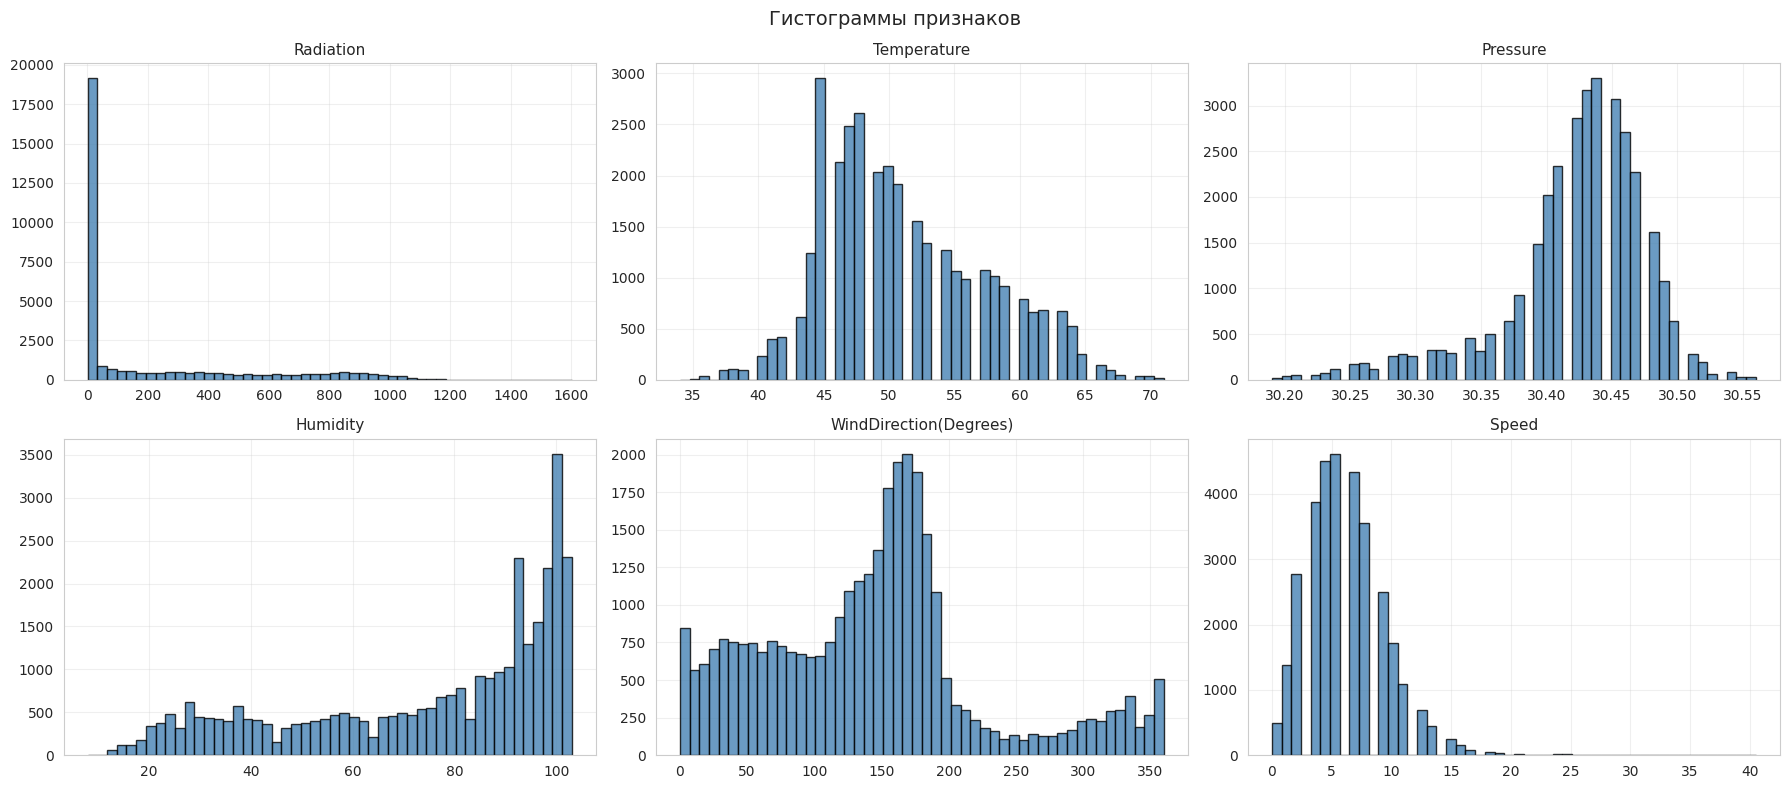

In [ ]:
cols_hist = ["Radiation", "Temperature", "Pressure", "Humidity",
             "WindDirection(Degrees)", "Speed"]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols_hist):
    ax.hist(df[col], bins=50, color="steelblue", edgecolor="black", alpha=0.8)
    ax.set_title(col, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle("Гистограммы признаков", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def normality_report(series, name):
    s = series.dropna().values
    s_sh = s if len(s) <= 5000 else np.random.choice(s, 5000, replace=False)
    sh_p = stats.shapiro(s_sh)[1]
    dp_p = stats.normaltest(s)[1]
    ks_p = stats.kstest((s - s.mean()) / s.std(), "norm")[1]

    v_sh = "норм." if sh_p > 0.05 else "не норм."
    v_dp = "норм." if dp_p > 0.05 else "не норм."
    v_ks = "норм." if ks_p > 0.05 else "не норм."

    print(f"{name:>22} | Shapiro p={sh_p:.2e} ({v_sh}) | "
          f"D'Agostino p={dp_p:.2e} ({v_dp}) | "
          f"KS p={ks_p:.2e} ({v_ks})")

print(f"{'признак':>22} | тесты нормальности")
for col in ["Radiation", "Temperature", "Pressure", "Humidity",
            "WindDirection(Degrees)", "Speed"]:
    normality_report(df[col], col)

               признак | тесты нормальности
             Radiation | Shapiro p=1.88e-69 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
           Temperature | Shapiro p=1.00e-32 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
              Pressure | Shapiro p=1.08e-44 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
              Humidity | Shapiro p=1.00e-53 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
WindDirection(Degrees) | Shapiro p=2.61e-38 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=4.60e-311 (не норм.)
                 Speed | Shapiro p=3.92e-45 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)


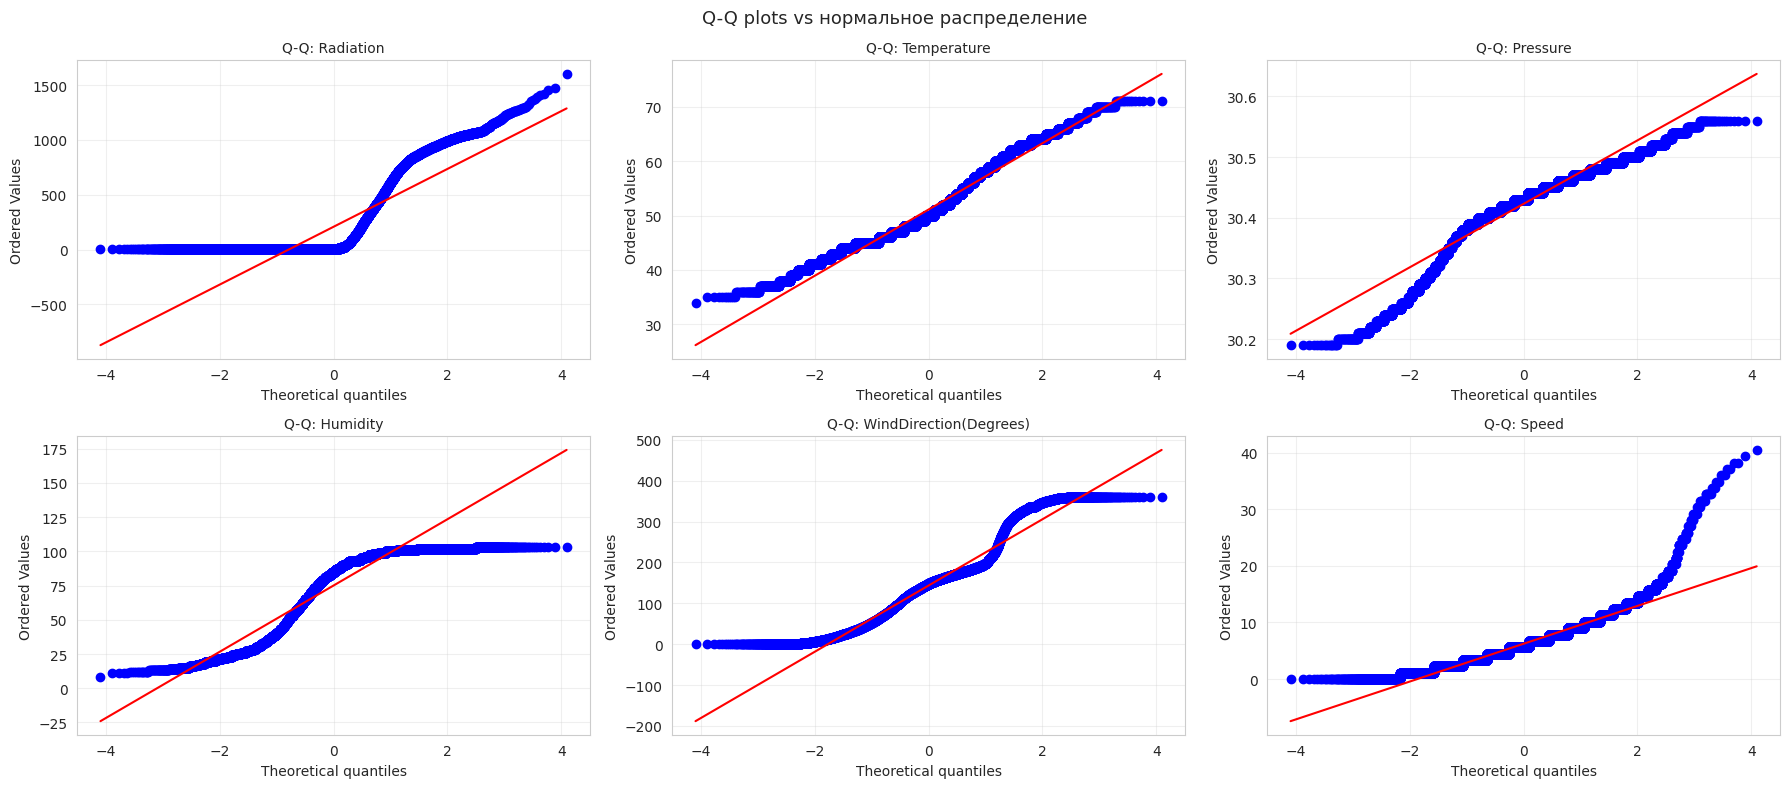

               признак | тесты нормальности
             Radiation | Shapiro p=1.76e-70 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
           Temperature | Shapiro p=5.99e-35 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
              Pressure | Shapiro p=3.21e-46 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
              Humidity | Shapiro p=4.15e-54 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)
WindDirection(Degrees) | Shapiro p=1.96e-38 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=4.60e-311 (не норм.)
                 Speed | Shapiro p=2.31e-45 (не норм.) | D'Agostino p=0.00e+00 (не норм.) | KS p=0.00e+00 (не норм.)


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols_hist):
    stats.probplot(df[col].dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q: {col}", fontsize=10)
    ax.grid(alpha=0.3)
plt.suptitle("Q-Q plots vs нормальное распределение", fontsize=13)
plt.tight_layout()
plt.show()


print(f"{'признак':>22} | тесты нормальности")
for col in cols_hist:
    normality_report(df[col], col)

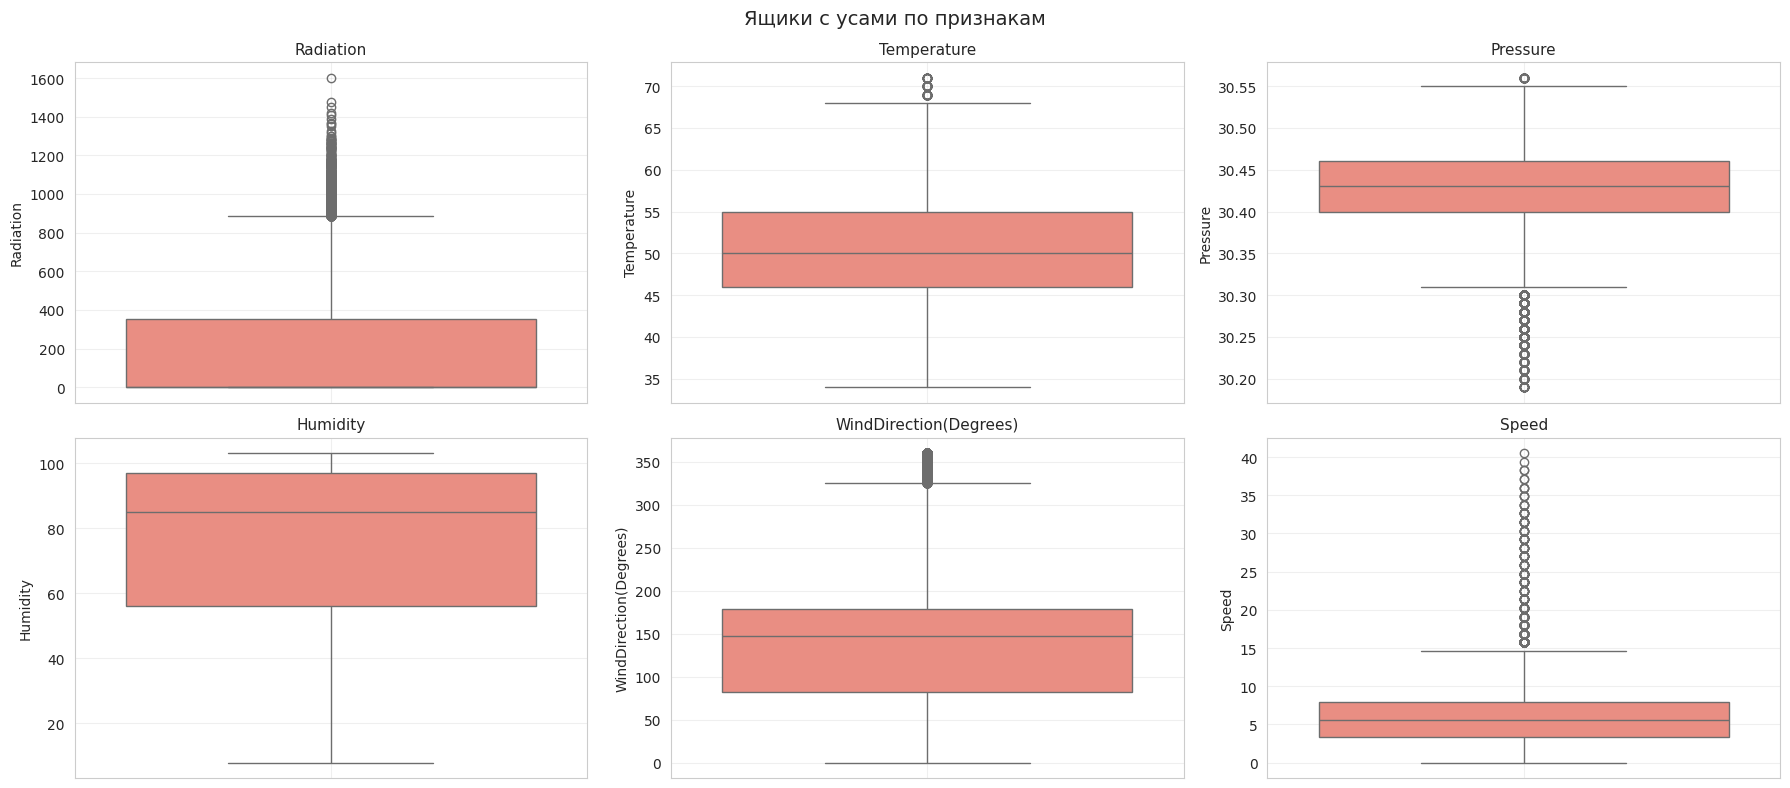

               признак | выбросов |  доля, % | границы
             Radiation |     1965 |    6.012 | [-528.277; 883.742]
           Temperature |       89 |    0.272 | [32.500; 68.500]
              Pressure |     1662 |    5.085 | [30.310; 30.550]
              Humidity |        0 |    0.000 | [-5.500; 158.500]
WindDirection(Degrees) |     1618 |    4.950 | [-63.396; 324.934]
                 Speed |      479 |    1.465 | [-3.380; 14.620]


In [ ]:
numeric_all = ["Radiation", "Temperature", "Pressure", "Humidity",
               "WindDirection(Degrees)", "Speed"]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), numeric_all):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle("Ящики с усами по признакам", fontsize=14)
plt.tight_layout()
plt.show()

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((series < low) | (series > high)).sum())
    return n_out, low, high

print(f"{'признак':>22} | {'выбросов':>8} | {'доля, %':>8} | границы")
for col in numeric_all:
    n_out, lo, hi = iqr_outliers(df[col])
    share = 100 * n_out / len(df)
    print(f"{col:>22} | {n_out:>8} | {share:>8.3f} | [{lo:.3f}; {hi:.3f}]")

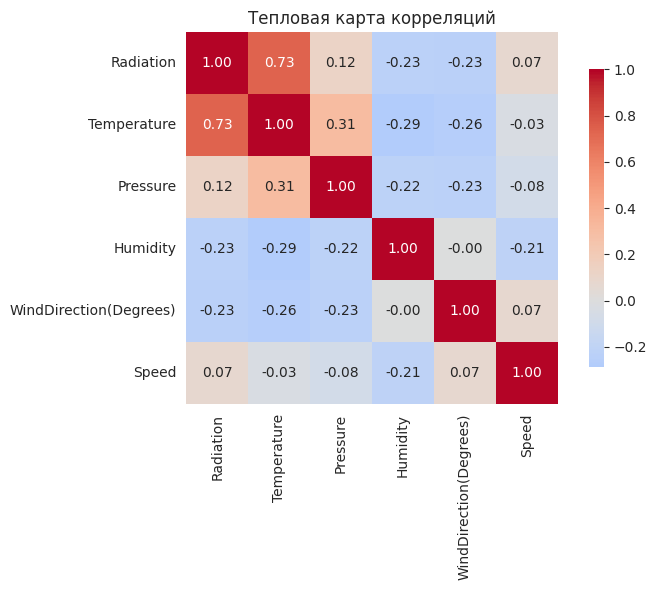

Корреляции признаков с Radiation:
Temperature               0.735
Pressure                  0.119
Speed                     0.074
Humidity                 -0.226
WindDirection(Degrees)   -0.230
Name: Radiation, dtype: float64


In [ ]:
corr_cols = ["Radiation", "Temperature", "Pressure", "Humidity",
             "WindDirection(Degrees)", "Speed"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Тепловая карта корреляций")
plt.tight_layout()
plt.show()

corr_with_y = corr_matrix["Radiation"].drop("Radiation").sort_values(ascending=False)
print("Корреляции признаков с Radiation:")
print(corr_with_y.round(3))

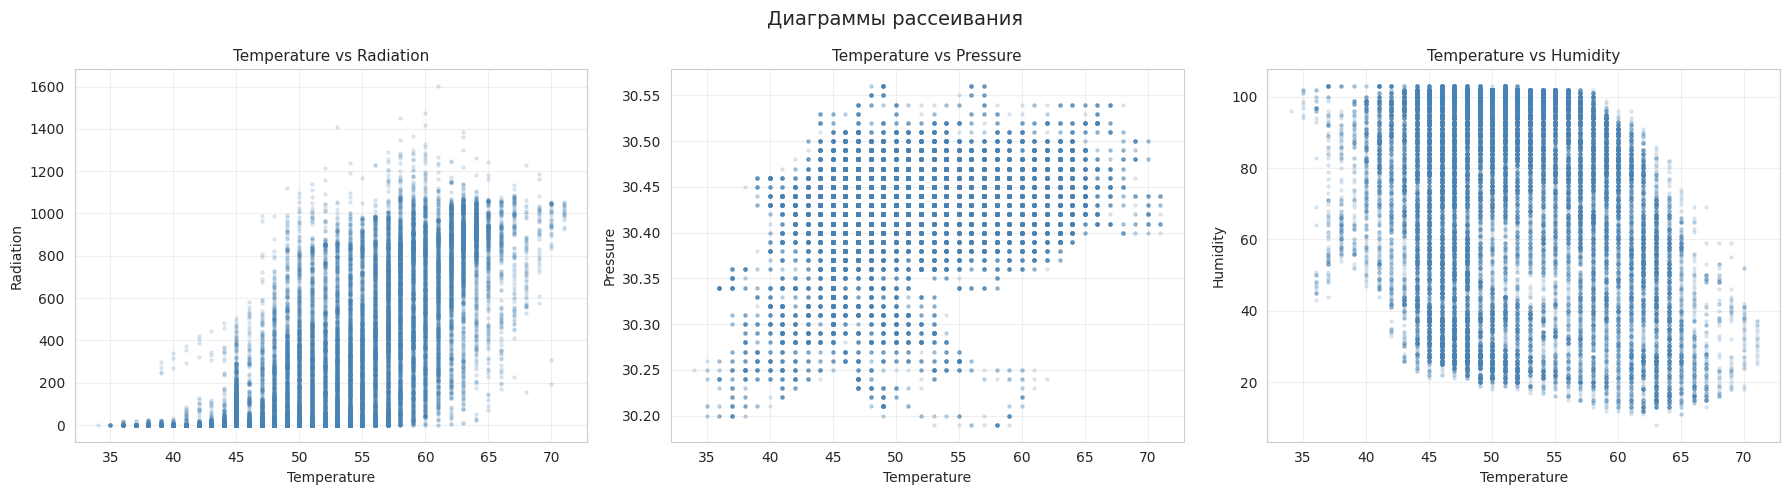

In [ ]:
pairs = [
    ("Temperature", "Radiation",  "Temperature vs Radiation"),
    ("Temperature", "Pressure",   "Temperature vs Pressure"),
    ("Temperature", "Humidity",   "Temperature vs Humidity"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x_col, y_col, title) in zip(axes, pairs):
    ax.scatter(df[x_col], df[y_col], alpha=0.15, s=5, color="steelblue")
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.3)

plt.suptitle("Диаграммы рассеивания", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
display(df[numeric_all].describe().T)

ext_stats = pd.DataFrame({
    "mean":   df[numeric_all].mean(),
    "median": df[numeric_all].median(),
    "std":    df[numeric_all].std(),
    "min":    df[numeric_all].min(),
    "max":    df[numeric_all].max(),
})
display(ext_stats.round(3))

,count,mean,std,min,25%,50%,75%,max
Radiation,32686.0,207.124697,315.916387,1.11,1.2300,2.66,354.235,1601.26
Temperature,32686.0,51.103255,6.201157,34.00,46.0000,50.00,55.000,71.00
Pressure,32686.0,30.422879,0.054673,30.19,30.4000,30.43,30.460,30.56
Humidity,32686.0,75.016307,25.990219,8.00,56.0000,85.00,97.000,103.00
WindDirection(Degrees),32686.0,143.489821,83.167500,0.09,82.2275,147.70,179.310,359.95
Speed,32686.0,6.243869,3.490474,0.00,3.3700,5.62,7.870,40.50


,mean,median,std,min,max
Radiation,207.125,2.66,315.916,1.11,1601.26
Temperature,51.103,50.00,6.201,34.00,71.00
Pressure,30.423,30.43,0.055,30.19,30.56
Humidity,75.016,85.00,25.990,8.00,103.00
WindDirection(Degrees),143.490,147.70,83.167,0.09,359.95
Speed,6.244,5.62,3.490,0.00,40.50


## 6. Оценка пропусков

In [ ]:
# Явные NaN, прям в таблице типо
miss = df.isnull().mean() * 100
miss_nz = miss[miss > 0].sort_values(ascending=False)
print("Явные пропуски (%):")
print(miss_nz if len(miss_nz) else "нет")

print("Пропуски в X после преобразований (%):")
print((X.isnull().mean() * 100).round(3).sort_values(ascending=False).head())

# Скрытые пропуски, просчеты по измерениям, то есть в какой-то момент времени просто не мерили (возможно избыточно)
ts_index = pd.DatetimeIndex(df["datetime"]).sort_values()
gaps = pd.Series(ts_index).diff()
expected = gaps.median()
big = gaps[gaps > 2 * expected]
print(f"Ожидаемый шаг: {expected}")
print(f"Разрывов (> 2× шага): {len(big)}")
print("Дубликатов времени:", ts_index.duplicated().sum())

Явные пропуски (%):
нет
Пропуски в X после преобразований (%):
UNIXTime       0.0
Data           0.0
Time           0.0
Temperature    0.0
Pressure       0.0
dtype: float64
Ожидаемый шаг: 0 days 00:05:00
Разрывов (> 2× шага): 193
Дубликатов времени: 0


## 7. Вариант ML-задачи

Y (Radiation) — непрерывная числовая, ак что задача регрессии.

### Итоговая формулировка задачи

Тип: регрессия.
Цель: предсказать Radiation по метеопризнакам и времени.

Обоснование:
- Y непрерывна, классы не заданы, так что не классификация.
- Тут таргет явно написан, то есть с учителем, так что не кластеризация.
